<a href="https://colab.research.google.com/github/MilkySon/Quality-Management/blob/main/RP3_%EA%B7%B8%EB%A6%BC_%EA%B7%B8%EB%A6%AC%EA%B8%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. 필요한 라이브러리 설치 및 임포트
import pandas as pd
import matplotlib.pyplot as plt

# 2. 엑셀 파일 업로드 코드 (코랩 실행 시 파일 선택 창이 뜸)
from google.colab import files
uploaded = files.upload()


Saving Prajapati_2012_Table1A.xlsx to Prajapati_2012_Table1A.xlsx


In [13]:

# 업로드한 파일명 확인 후 파일 경로 지정 (예: 'Prajapati_2012_Table1A.xlsx')
file_name = list(uploaded.keys())[0]

# 3. 데이터 읽어오기
df = pd.read_excel(file_name, header=3, index_col=0)


In [14]:
df.head()

,X1,X2,X3,X4,X̄,R
S. NO.,,,,,,
1,62.05,62.05,62.04,62.05,62.0475,0.01
2,62.04,61.96,61.97,62.04,62.0025,0.08
3,61.99,61.98,61.99,62.04,62.0000,0.06
4,62.04,62.02,62.02,62.05,62.0325,0.03
5,62.05,62.04,62.05,62.04,62.0450,0.01


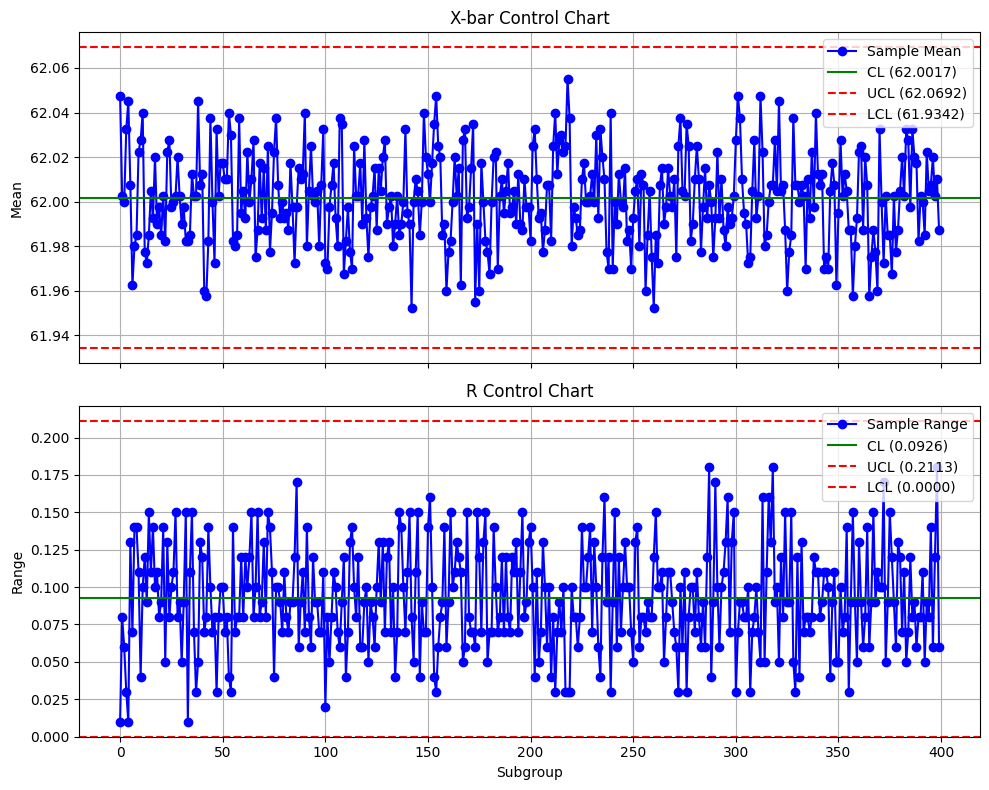

In [15]:

# 4. 부분군 데이터 추출 (X1, X2, X3, X4)
subgroups = df[['X1', 'X2', 'X3', 'X4']]

# 5. X-bar(평균) 및 R(범위) 계산
# 각 부분군의 평균 (X-bar)
x_bar = subgroups.mean(axis=1)
# 각 부분군의 범위 (R = 최댓값 - 최솟값)
r_range = subgroups.max(axis=1) - subgroups.min(axis=1)

# 전체 평균의 평균 (Grand Mean, X-double-bar)
grand_mean = x_bar.mean()
# 평균 범위 (R-bar)
r_bar = r_range.mean()

# 관리도 계수 (n=4일 때의 통계적 관리도 상수: A2 = 0.729, D3 = 0, D4 = 2.282)
# n=4 기준 표준 상수 적용
A2 = 0.729
D3 = 0
D4 = 2.282

# X-bar 관리도 한계선 계산
xbar_ucl = grand_mean + A2 * r_bar
xbar_lcl = grand_mean - A2 * r_bar

# R 관리도 한계선 계산
r_ucl = D4 * r_bar
r_lcl = D3 * r_bar

# 6. 관리도 시각화
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# (1) X-bar Chart
axes[0].plot(x_bar.values, marker='o', color='b', linestyle='-', label='Sample Mean')
axes[0].axhline(grand_mean, color='g', linestyle='-', label=f'CL ({grand_mean:.4f})')
axes[0].axhline(xbar_ucl, color='r', linestyle='--', label=f'UCL ({xbar_ucl:.4f})')
axes[0].axhline(xbar_lcl, color='r', linestyle='--', label=f'LCL ({xbar_lcl:.4f})')
axes[0].set_title('X-bar Control Chart')
axes[0].set_ylabel('Mean')
axes[0].legend(loc='upper right')
axes[0].grid(True)

# (2) R Chart
axes[1].plot(r_range.values, marker='o', color='b', linestyle='-', label='Sample Range')
axes[1].axhline(r_bar, color='g', linestyle='-', label=f'CL ({r_bar:.4f})')
axes[1].axhline(r_ucl, color='r', linestyle='--', label=f'UCL ({r_ucl:.4f})')
axes[1].axhline(r_lcl, color='r', linestyle='--', label=f'LCL ({r_lcl:.4f})')
axes[1].set_title('R Control Chart')
axes[1].set_xlabel('Subgroup')
axes[1].set_ylabel('Range')
axes[1].legend(loc='upper right')
axes[1].grid(True)

plt.tight_layout()
plt.show()